<a href="https://colab.research.google.com/github/atman500/atman500/blob/main/Random_forest_using_simple_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy  as np
from google.colab import files

In [9]:
Late_Payments=[['1','2','1','4','5','4']]

Credit_Risk_Level=[['1','1','2','4','4','5']]

In [11]:
df=pd.DataFrame({

                 "NLate_Payments":Late_Payments,
                 "Credit_Risk_Level":Credit_Risk_Level
})
print(df)

       NLate_Payments   Credit_Risk_Level
0  [1, 2, 1, 4, 5, 4]  [1, 1, 2, 4, 4, 5]


In [12]:
df = pd.DataFrame({
    "NLate_Payments": Late_Payments[0],
    "Credit_Risk_Level": Credit_Risk_Level[0]
})
print(df)

  NLate_Payments Credit_Risk_Level
0              1                 1
1              2                 1
2              1                 2
3              4                 4
4              5                 4
5              4                 5


In [13]:
df.describe()

,NLate_Payments,Credit_Risk_Level
count,6,6
unique,4,4
top,1,1
freq,2,2


In [15]:
from sklearn.ensemble import RandomForestClassifier

# Convert features to numeric integers
df['NLate_Payments'] = df['NLate_Payments'].astype(int)
df['Credit_Risk_Level'] = df['Credit_Risk_Level'].astype(int)

# Define feature (X) and target (y)
X = df[['NLate_Payments']]
y = df['Credit_Risk_Level']

# Initialize and fit the Random Forest Classifier
rf = RandomForestClassifier(n_estimators=3, random_state=42)
rf.fit(X, y)

# Print the predictions and feature importance
predictions = rf.predict(X)
print("Predictions:", predictions)
print("Feature Importances:", rf.feature_importances_)

Predictions: [2 1 2 4 4 4]
Feature Importances: [1.]


In [16]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import warnings

# Suppress OOB warnings expected when using very few trees (T=3) on a tiny dataset
warnings.filterwarnings('ignore')

# 1. DataFrame Initialization
data = {
    'X1': [1, 2, 1, 4, 5, 4],
    'X2': [1, 1, 2, 4, 4, 5],
    'Class': [-1, -1, -1, 1, 1, 1]
}
df = pd.DataFrame(data)
X = df[['X1', 'X2']]
y = df['Class']

# 2. Model Configuration
# max_features=1 restricts the algorithm to evaluate only 1 variable per split (m=1)
rf_model = RandomForestClassifier(
    n_estimators=3,
    max_features=1,
    oob_score=True,
    random_state=42
)

# 3. Training and Internal Validation
rf_model.fit(X, y)

# oob_score_ returns the accuracy; subtracting from 1 gives the error rate
oob_accuracy = rf_model.oob_score_
oob_error_rate = 1 - oob_accuracy
print(f"OOB Error Rate: {oob_error_rate * 100:.1f}%\n")

# 4. Majority Vote Prediction
# Formatting the new client data as a 2D array: [[X1, X2]]
new_client = pd.DataFrame({'X1': [4], 'X2': [2]})
prediction = rf_model.predict(new_client)
print(f"New Client (X1=4, X2=2) Predicted Class: {prediction[0]}\n")

# 5. Tree Extraction (Advanced Step)
print("Internal Architecture of the Random Forest:")
for i, tree in enumerate(rf_model.estimators_):
    max_depth = tree.tree_.max_depth
    node_count = tree.tree_.node_count
    print(f"Tree {i+1}: Max Depth = {max_depth}, Total Nodes = {node_count}")

OOB Error Rate: 0.0%

New Client (X1=4, X2=2) Predicted Class: 1

Internal Architecture of the Random Forest:
Tree 1: Max Depth = 1, Total Nodes = 3
Tree 2: Max Depth = 1, Total Nodes = 3
Tree 3: Max Depth = 1, Total Nodes = 3


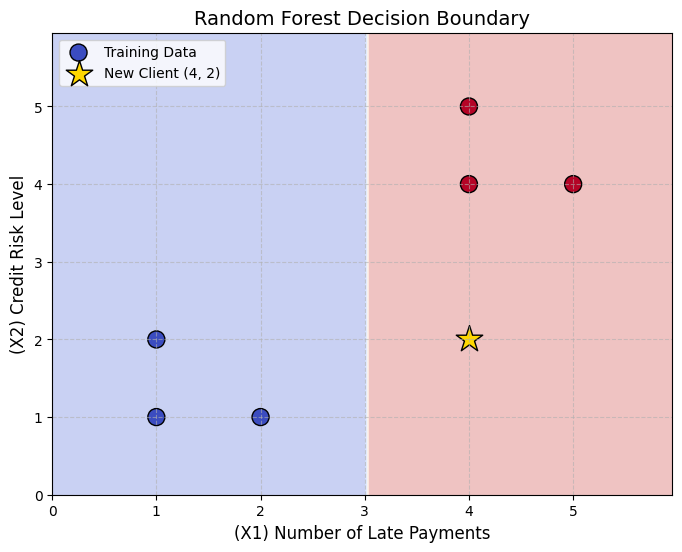

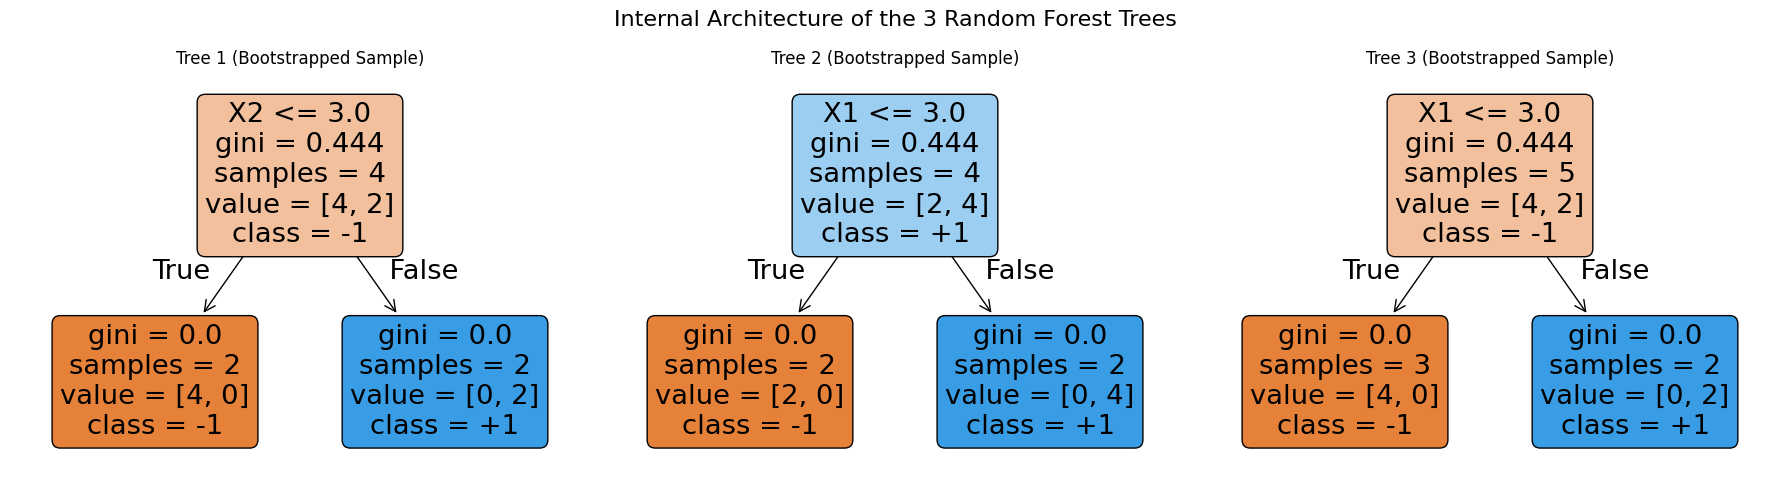

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# ---------------------------------------------------------
# Plot 1: The Decision Boundary of the Random Forest
# ---------------------------------------------------------
plt.figure(figsize=(8, 6))

# Create a mesh grid spanning the feature space
x_min, x_max = X['X1'].min() - 1, X['X1'].max() + 1
y_min, y_max = X['X2'].min() - 1, X['X2'].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

# Predict the class for every point on the grid
mesh_predictions = rf_model.predict(np.c_[xx.ravel(), yy.ravel()])
mesh_predictions = mesh_predictions.reshape(xx.shape)

# Draw the colored decision regions
plt.contourf(xx, yy, mesh_predictions, alpha=0.3, cmap='coolwarm')

# Plot the original dataset points
scatter = plt.scatter(X['X1'], X['X2'], c=y, cmap='coolwarm',
                      edgecolors='k', s=150, label='Training Data')

# Plot the new client (X1=4, X2=2) as a distinct star
plt.scatter(4, 2, c='gold', marker='*', edgecolors='k', s=400, label='New Client (4, 2)')

plt.title('Random Forest Decision Boundary', fontsize=14)
plt.xlabel('(X1) Number of Late Payments', fontsize=12)
plt.ylabel('(X2) Credit Risk Level', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# ---------------------------------------------------------
# Plot 2: Visualizing the 3 Independent Trees
# ---------------------------------------------------------
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
fig.suptitle('Internal Architecture of the 3 Random Forest Trees', fontsize=16)

for i, tree in enumerate(rf_model.estimators_):
    plot_tree(tree,
              feature_names=['X1', 'X2'],
              class_names=['-1', '+1'],
              filled=True,
              rounded=True,
              ax=axes[i])
    axes[i].set_title(f'Tree {i+1} (Bootstrapped Sample)')

plt.tight_layout()
plt.show()